# Fig. 2 — cosine-similarity heatmaps (vector PDFs)

Reads `prompt_similarities.txt` and `output_similarities.txt` from `data/surface_vs_behaviour/` (the two 16 × 16 matrices of the Section 5.1 experiment, at the 2-decimal precision printed in the figure) and writes two vector PDFs:

- `fig_prompt_similarity.pdf`
- `fig_output_similarity.pdf`

**How to run:** in Colab, cell 1 asks you to upload the two `.txt` files; run the rest top to bottom. Locally, put the two files next to the notebook.

Text is embedded as real vector text, so the numbers stay selectable and crisp at any zoom.

In [1]:
# --- Cell 1: upload the two matrix files (skip if you mounted Drive instead) ---
try:
    from google.colab import files
    print("Select prompt_similarities.txt and output_similarities.txt")
    files.upload()
except ImportError:
    print("Not running in Colab — make sure the .txt files sit next to this notebook.")

Select prompt_similarities.txt and output_similarities.txt


Saving output_similarities.txt to output_similarities.txt
Saving prompt_similarities.txt to prompt_similarities.txt


In [2]:
# --- Cell 2: imports + global style ---
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# Keep text as text in the PDF (TrueType), not as traced outlines.
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['savefig.bbox'] = 'tight'

LABELS = [f"P{i}" for i in range(1, 17)]
print("matplotlib", mpl.__version__, "| seaborn", sns.__version__)

matplotlib 3.10.0 | seaborn 0.13.2


In [3]:
# --- Cell 3: load + sanity-check the matrices ---
def load_matrix(path, n=16):
    M = np.loadtxt(path)
    assert M.shape == (n, n), f"{path}: expected {n}x{n}, got {M.shape}"
    if not np.allclose(np.diag(M), 1.0, atol=1e-6):
        print(f"  warning: {path} diagonal is not all 1.00")
    if not np.allclose(M, M.T, atol=1e-6):
        print(f"  warning: {path} is not symmetric")
    return M

prompt_sim = load_matrix('prompt_similarities.txt')
output_sim = load_matrix('output_similarities.txt')

for name, M in [('prompt', prompt_sim), ('output', output_sim)]:
    off = M[~np.eye(16, dtype=bool)]
    print(f"{name}: min={off.min():.2f}  max={off.max():.2f}  mean={off.mean():.3f}")

prompt: min=0.44  max=0.90  mean=0.694
output: min=0.22  max=0.93  mean=0.671


In [4]:
# --- Cell 4: the plotting function ---
def make_heatmap(matrix, title, outfile, labels=LABELS,
                 figsize=(12.5, 10.5), dpi=300):
    """Render one similarity matrix and save it as a vector PDF.

    Annotation colour is handled by seaborn: it computes the luminance of each
    cell's fill and flips the text between black and white, so dark viridis
    cells get white numbers and the bright yellow diagonal gets black ones.
    Colour limits are pinned to 0-1 so both figures share one scale.
    """
    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        matrix,
        vmin=0.0, vmax=1.0,
        cmap='viridis',
        annot=True,
        fmt='.2f',
        annot_kws={'fontsize': 13},
        square=True,
        linewidths=0,
        xticklabels=labels,
        yticklabels=labels,
        cbar=True,
        cbar_kws={'shrink': 0.82, 'pad': 0.02, 'ticks': np.arange(0, 1.01, 0.2)},
        ax=ax,
    )

    ax.set_title(title, fontsize=22, pad=18)
    ax.set_xlabel('Prompt ID', fontsize=17, labelpad=12)
    ax.set_ylabel('Prompt ID', fontsize=17, labelpad=12)
    ax.tick_params(axis='x', labelsize=14, rotation=0, length=3)
    ax.tick_params(axis='y', labelsize=14, rotation=90, length=3)
    for lbl in ax.get_yticklabels():
        lbl.set_va('center')

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=14, length=3)
    cbar.outline.set_visible(False)

    fig.savefig(outfile, format='pdf', dpi=dpi, bbox_inches='tight', pad_inches=0.25)
    print(f"wrote {outfile}")
    plt.show()
    plt.close(fig)

wrote fig_prompt_similarity.pdf


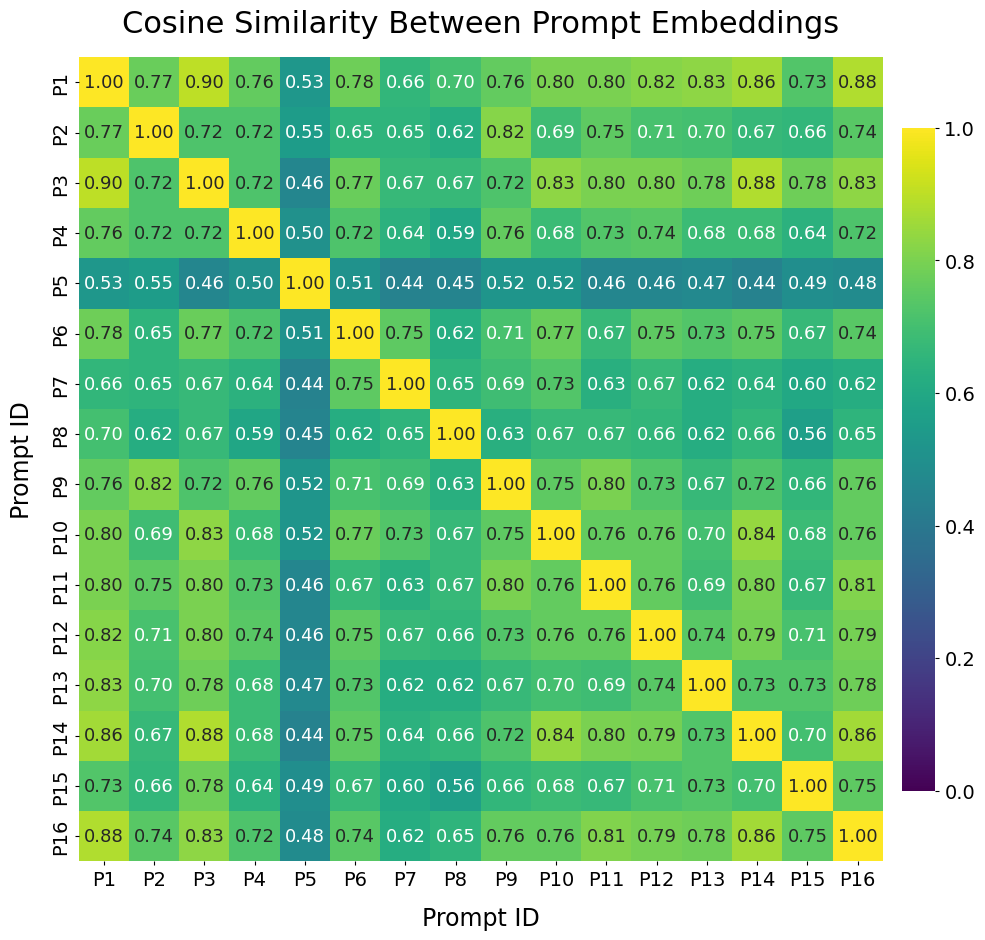

wrote fig_output_similarity.pdf


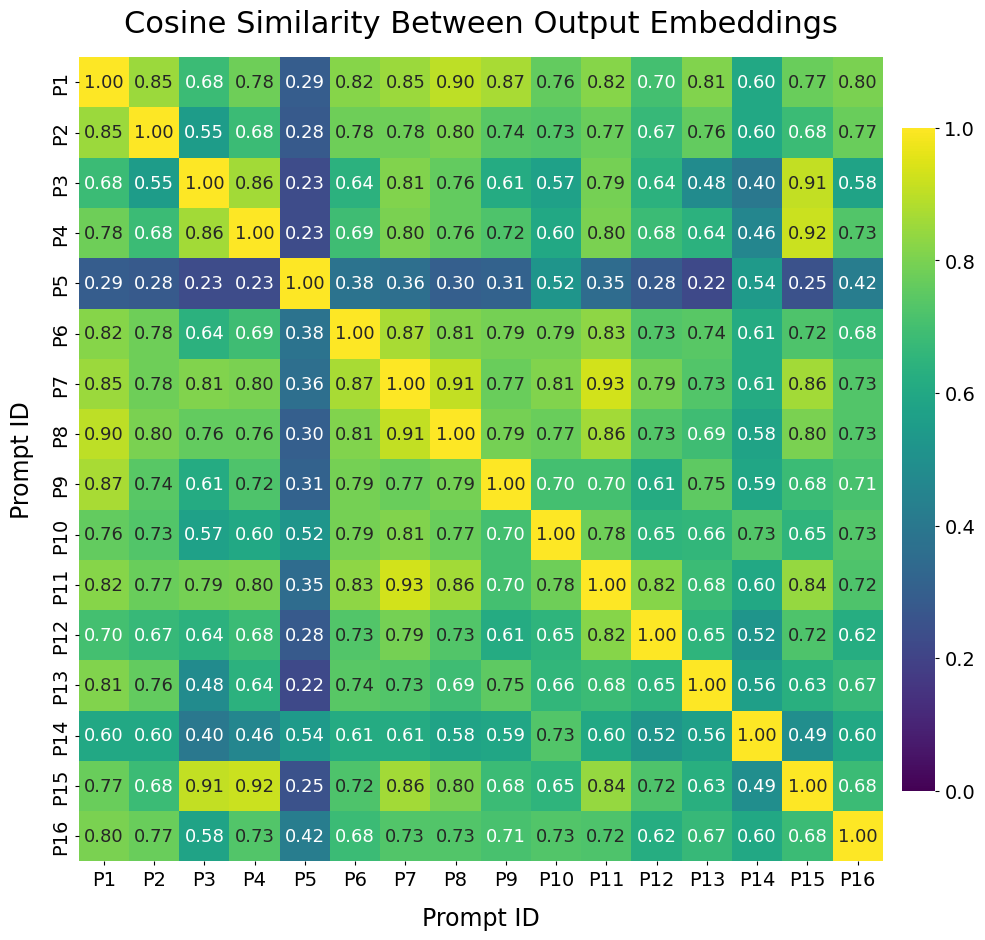

In [5]:
# --- Cell 5: render both figures ---
make_heatmap(prompt_sim,
             'Cosine Similarity Between Prompt Embeddings',
             'fig_prompt_similarity.pdf')

make_heatmap(output_sim,
             'Cosine Similarity Between Output Embeddings',
             'fig_output_similarity.pdf')

In [6]:
# --- Cell 6 (optional): also save 600-dpi PNG/TIFF if a journal demands raster ---
RASTER = False
if RASTER:
    for M, t, stem in [(prompt_sim, 'Cosine Similarity Between Prompt Embeddings', 'fig_prompt_similarity'),
                       (output_sim, 'Cosine Similarity Between Output Embeddings', 'fig_output_similarity')]:
        make_heatmap(M, t, f'{stem}.png', dpi=600)

In [7]:
# --- Cell 7: download ---
try:
    from google.colab import files
    files.download('fig_prompt_similarity.pdf')
    files.download('fig_output_similarity.pdf')
except ImportError:
    print("Not in Colab — PDFs are in the working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>